In [1]:
# Decision Tree Classification using Gini Impurity and Entropy
# Data Analytics and Visualisation (DAV)

# 1. Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# 2. Load the Dataset
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['Target'] = iris.target

print("First Five Rows of Dataset:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nDataset Description:")
print(df.describe())

First Five Rows of Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Target  
0       0  
1       0  
2       0  
3       0  
4       0  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Target

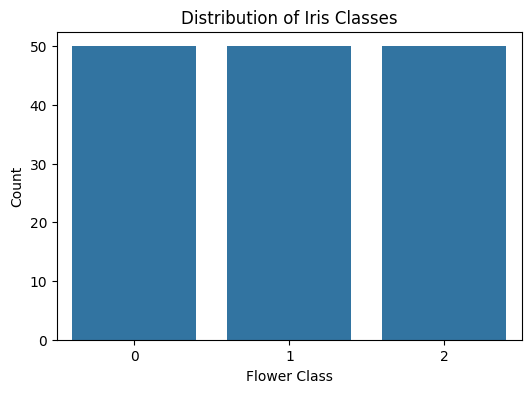

In [3]:
# 3. Data Visualisation - Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Target', data=df)
plt.title("Distribution of Iris Classes")
plt.xlabel("Flower Class")
plt.ylabel("Count")
plt.show()

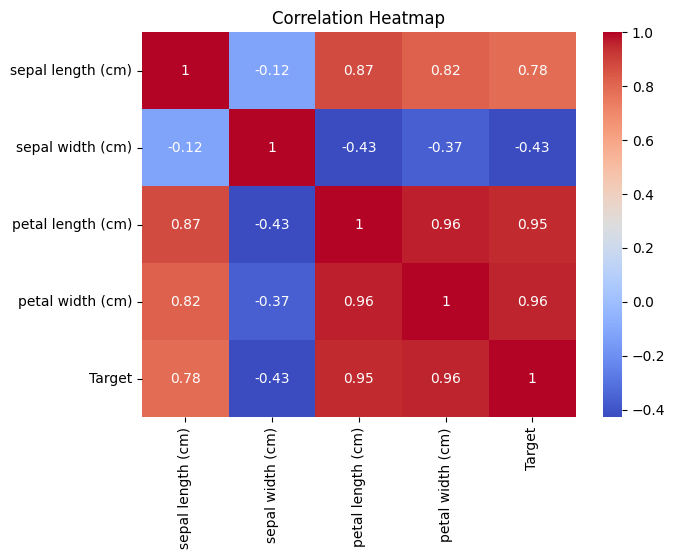

In [4]:
# 4. Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [5]:
# 5. Split Dataset into Training and Testing Data
X = df.drop('Target', axis=1)
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))



Training Samples: 120
Testing Samples: 30


In [6]:
# 6. Calculate Gini Impurity
def gini_impurity(y):
    probabilities = np.bincount(y) / len(y)
    return 1 - np.sum(probabilities ** 2)

print("\nGini Impurity:", gini_impurity(y_train))



Gini Impurity: 0.6665277777777778


In [7]:
# 7. Calculate Entropy
def entropy(y):
    probabilities = np.bincount(y) / len(y)
    probabilities = probabilities[probabilities > 0]
    return -np.sum(probabilities * np.log2(probabilities))

print("Entropy:", entropy(y_train))

Entropy: 1.5846619079379884


In [8]:
# 8. Train Decision Tree using Gini Impurity
model_gini = DecisionTreeClassifier(
    criterion='gini', random_state=42
)

model_gini.fit(X_train, y_train)

y_pred_gini = model_gini.predict(X_test)

print("\nDecision Tree using Gini Impurity")
print("Accuracy:",
      accuracy_score(y_test, y_pred_gini) * 100, "%")


Decision Tree using Gini Impurity
Accuracy: 100.0 %


In [9]:
# 9. Train Decision Tree using Entropy
model_entropy = DecisionTreeClassifier(
    criterion='entropy', random_state=42
)

model_entropy.fit(X_train, y_train)

y_pred_entropy = model_entropy.predict(X_test)

print("\nDecision Tree using Entropy")
print("Accuracy:",
      accuracy_score(y_test, y_pred_entropy) * 100, "%")



Decision Tree using Entropy
Accuracy: 100.0 %


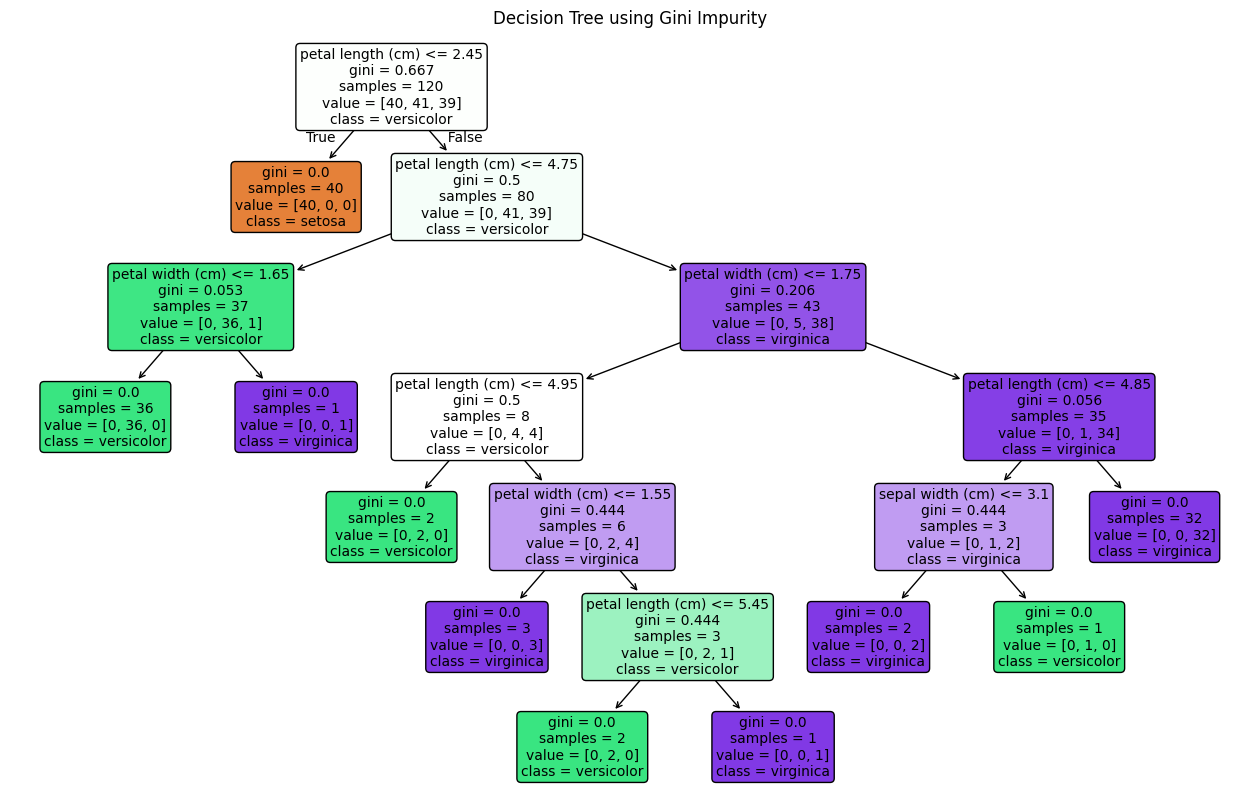

In [10]:
# 10. Visualise Decision Tree
plt.figure(figsize=(16, 10))

plot_tree(
    model_gini,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree using Gini Impurity")
plt.show()

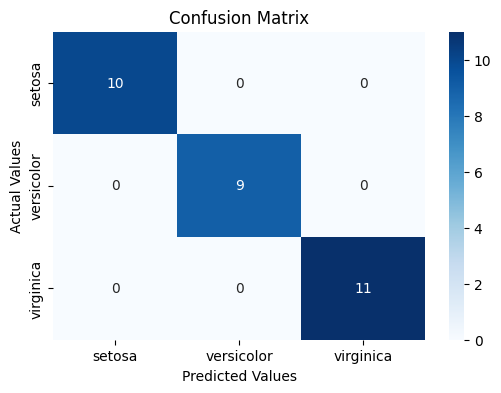

In [11]:
# 11. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_gini)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

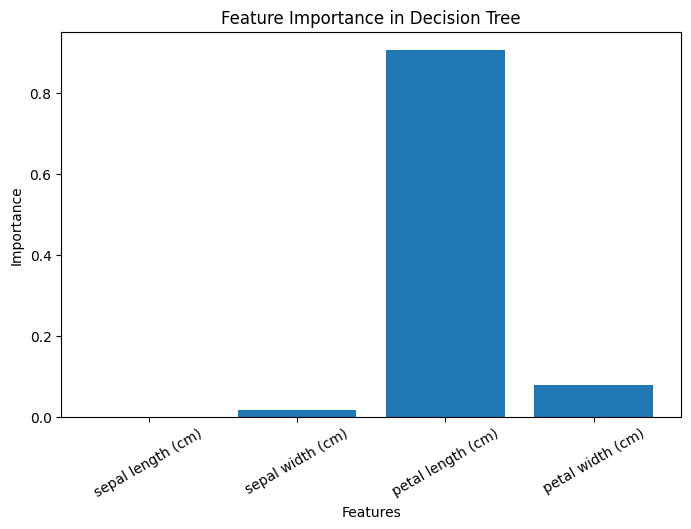

In [12]:
# 12. Feature Importance Visualisation
importance = model_gini.feature_importances_

plt.figure(figsize=(8, 5))

plt.bar(iris.feature_names, importance)

plt.title("Feature Importance in Decision Tree")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=30)
plt.show()


In [13]:
# 13. Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gini,
    target_names=iris.target_names
))


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [14]:
# 14. Final Result
print("\nFinal Result:")
print("Decision Tree Classification completed successfully.")
print("Gini Accuracy:",
      accuracy_score(y_test, y_pred_gini) * 100, "%")
print("Entropy Accuracy:",
      accuracy_score(y_test, y_pred_entropy) * 100, "%")


Final Result:
Decision Tree Classification completed successfully.
Gini Accuracy: 100.0 %
Entropy Accuracy: 100.0 %
